In [21]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import (train_test_split,GridSearchCV)
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score)
import warnings
warnings.filterwarnings('ignore')

In [22]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

In [66]:
df = pd.read_csv("Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [25]:
df.Churn.value_counts()

,count
Churn,
No,5174
Yes,1869


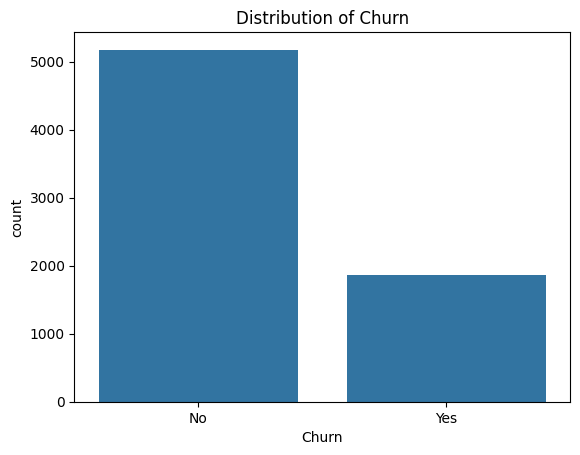

In [26]:
sns.countplot(x='Churn', data=df)
plt.title('Distribution of Churn')
plt.show()

In [27]:
df.drop(columns=['customerID'], inplace=True)

In [28]:
df = df[df['TotalCharges'] != ' ']
df['TotalCharges'] = df['TotalCharges'].astype(float)

In [29]:
df.isnull().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


In [30]:
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

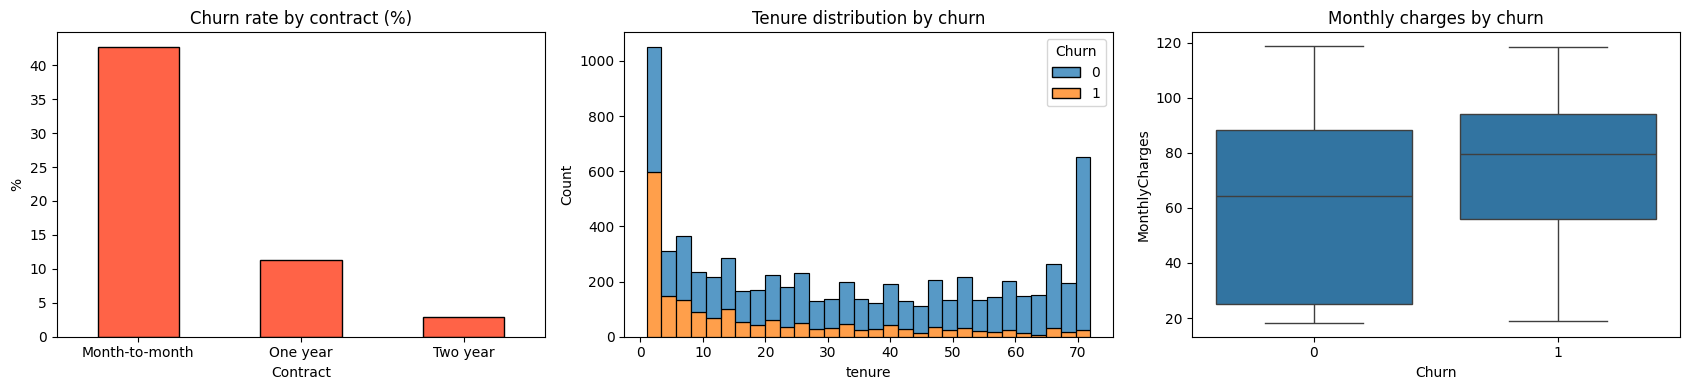

In [31]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))

(df.groupby('Contract')['Churn'].mean() * 100).plot.bar(ax=ax[0], color='tomato', edgecolor='black')
ax[0].set_title('Churn rate by contract (%)'); ax[0].set_ylabel('%'); ax[0].tick_params(axis='x', rotation=0)

sns.histplot(data=df, x='tenure', hue='Churn', bins=30, multiple='stack', ax=ax[1])
ax[1].set_title('Tenure distribution by churn')

sns.boxplot(data=df, x='Churn', y='MonthlyCharges', ax=ax[2])
ax[2].set_title('Monthly charges by churn')

plt.tight_layout(); plt.show()

In [32]:
print((df.groupby('InternetService')['Churn'].mean() * 100).round(1).to_string(), '\n')
print((df.groupby('PaymentMethod')['Churn'].mean() * 100).round(1).to_string())

InternetService
DSL            19.0
Fiber optic    41.9
No              7.4 

PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.3
Electronic check             45.3
Mailed check                 19.2


In [33]:
ADDON_SERVICES = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                  'TechSupport', 'StreamingTV', 'StreamingMovies']

def add_features(data):
    data = data.copy()
    data['n_services'] = (data[ADDON_SERVICES] == 'Yes').sum(axis=1)
    data['tenure_group'] = pd.cut(data['tenure'], bins=[-1, 12, 24, 48, 72],
                                  labels=['0-12', '13-24', '25-48', '49-72']).astype(str)
    data['avg_charge'] = data['TotalCharges'] / data['tenure'].clip(lower=1)
    return data

df = add_features(df)
df[['tenure', 'tenure_group', 'n_services', 'avg_charge']].head()

,tenure,tenure_group,n_services,avg_charge
0,1,0-12,1,29.850000
1,34,25-48,2,55.573529
2,2,0-12,2,54.075000
3,45,25-48,3,40.905556
4,2,0-12,0,75.825000


In [34]:
cat_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
            'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
            'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
            'PaperlessBilling', 'PaymentMethod',
            'tenure_group']

df = pd.get_dummies(df, columns=cat_cols)
df.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,n_services,avg_charge,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,PhoneService_No,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,tenure_group_0-12,tenure_group_13-24,tenure_group_25-48,tenure_group_49-72
0,0,1,29.85,29.85,0,1,29.850000,True,False,False,True,True,False,True,False,False,True,False,True,False,False,True,False,False,False,False,True,True,False,False,True,False,False,True,False,False,True,False,False,True,False,False,False,True,False,False,True,False,True,False,False,False
1,0,34,56.95,1889.50,0,2,55.573529,False,True,True,False,True,False,False,True,True,False,False,True,False,False,False,False,True,True,False,False,False,False,True,True,False,False,True,False,False,True,False,False,False,True,False,True,False,False,False,False,True,False,False,True,False
2,0,2,53.85,108.15,1,2,54.075000,False,True,True,False,True,False,False,True,True,False,False,True,False,False,False,False,True,False,False,True,True,False,False,True,False,False,True,False,False,True,False,False,True,False,False,False,True,False,False,False,True,True,False,False,False
3,0,45,42.30,1840.75,0,3,40.905556,False,True,True,False,True,False,True,False,False,True,False,True,False,False,False,False,True,True,False,False,False,False,True,False,False,True,True,False,False,True,False,False,False,True,False,True,False,True,False,False,False,False,False,True,False
4,0,2,70.70,151.65,1,0,75.825000,True,False,True,False,True,False,False,True,True,False,False,False,True,False,True,False,False,True,False,False,True,False,False,True,False,False,True,False,False,True,False,False,True,False,False,False,True,False,False,True,False,True,False,False,False


In [35]:
x = df.drop('Churn', axis=1)
y = df.Churn

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [36]:
x_train_raw = x_train.copy()
x_test_raw = x_test.copy()

In [37]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [38]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from xgboost import XGBClassifier

In [39]:
names = ['Logistic Regression', 'SVM', 'KNN', 'Decision Tree',
         'Random Forest', 'AdaBoost', 'XGBoost']

model_list = [
    LogisticRegression(max_iter=5000),
    SVC(kernel='rbf', gamma='scale', probability=True),
    KNeighborsClassifier(n_neighbors=5),
    DecisionTreeClassifier(random_state=42),
    RandomForestClassifier(n_estimators=100, random_state=42),
    AdaBoostClassifier(n_estimators=100, random_state=42),
    XGBClassifier(n_estimators=50, random_state=42)
]

In [40]:
results = []
predictions = {}

for name, model in zip(names, model_list):
    model.fit(x_train, y_train)
    y_pred_train = model.predict(x_train)
    y_pred = model.predict(x_test)
    predictions[name] = y_pred

    print('Train classification_report')
    print(classification_report(y_train, y_pred_train))
    print('test classification_report')
    print(classification_report(y_test, y_pred))

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred)
    })

Train classification_report
              precision    recall  f1-score   support

           0       0.85      0.90      0.87      4130
           1       0.67      0.55      0.60      1495

    accuracy                           0.81      5625
   macro avg       0.76      0.72      0.74      5625
weighted avg       0.80      0.81      0.80      5625

test classification_report
              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1033
           1       0.64      0.53      0.58       374

    accuracy                           0.80      1407
   macro avg       0.74      0.71      0.72      1407
weighted avg       0.79      0.80      0.79      1407

Train classification_report
              precision    recall  f1-score   support

           0       0.84      0.93      0.89      4130
           1       0.73      0.52      0.61      1495

    accuracy                           0.82      5625
   macro avg       0.79      0.73      0.75  

In [41]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values('F1-Score', ascending=False).reset_index(drop=True)
results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.795309,0.638710,0.529412,0.578947
1,AdaBoost,0.788913,0.622222,0.524064,0.568940
2,XGBoost,0.770434,0.576577,0.513369,0.543140
3,Random Forest,0.782516,0.617241,0.478610,0.539157
4,KNN,0.754087,0.537234,0.540107,0.538667
5,SVM,0.787491,0.640449,0.457219,0.533541
6,Decision Tree,0.728500,0.489529,0.500000,0.494709


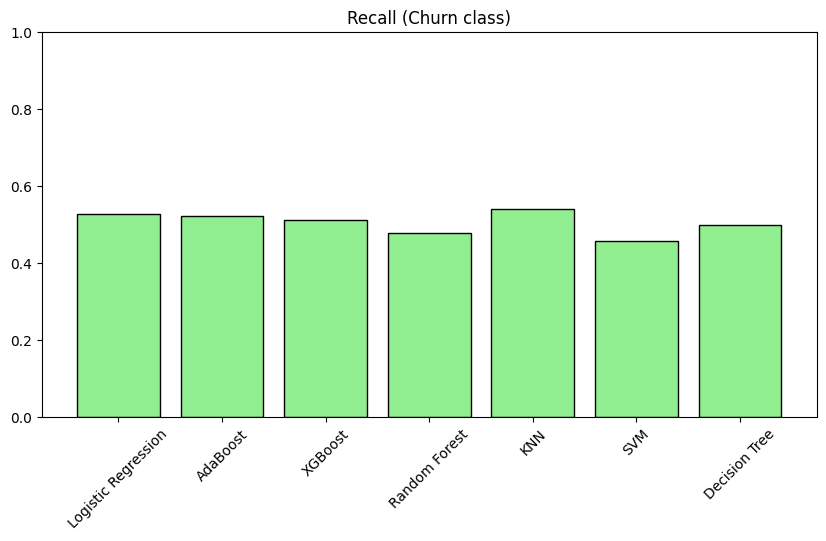

In [42]:
plt.figure(figsize=(10, 5))
plt.bar(results_df['Model'], results_df['Recall'], color='lightgreen', edgecolor='black')
plt.title('Recall (Churn class)')
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.show()

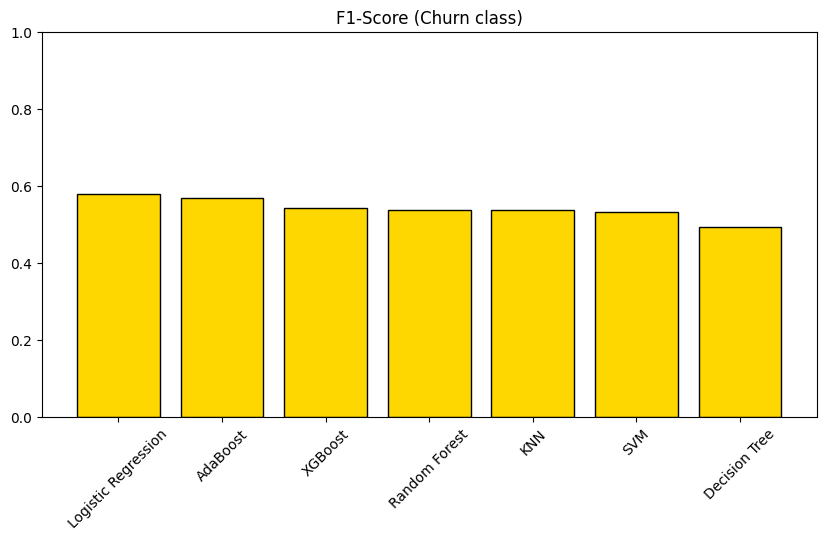

In [43]:
plt.figure(figsize=(10, 5))
plt.bar(results_df['Model'], results_df['F1-Score'], color='gold', edgecolor='black')
plt.title('F1-Score (Churn class)')
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.show()

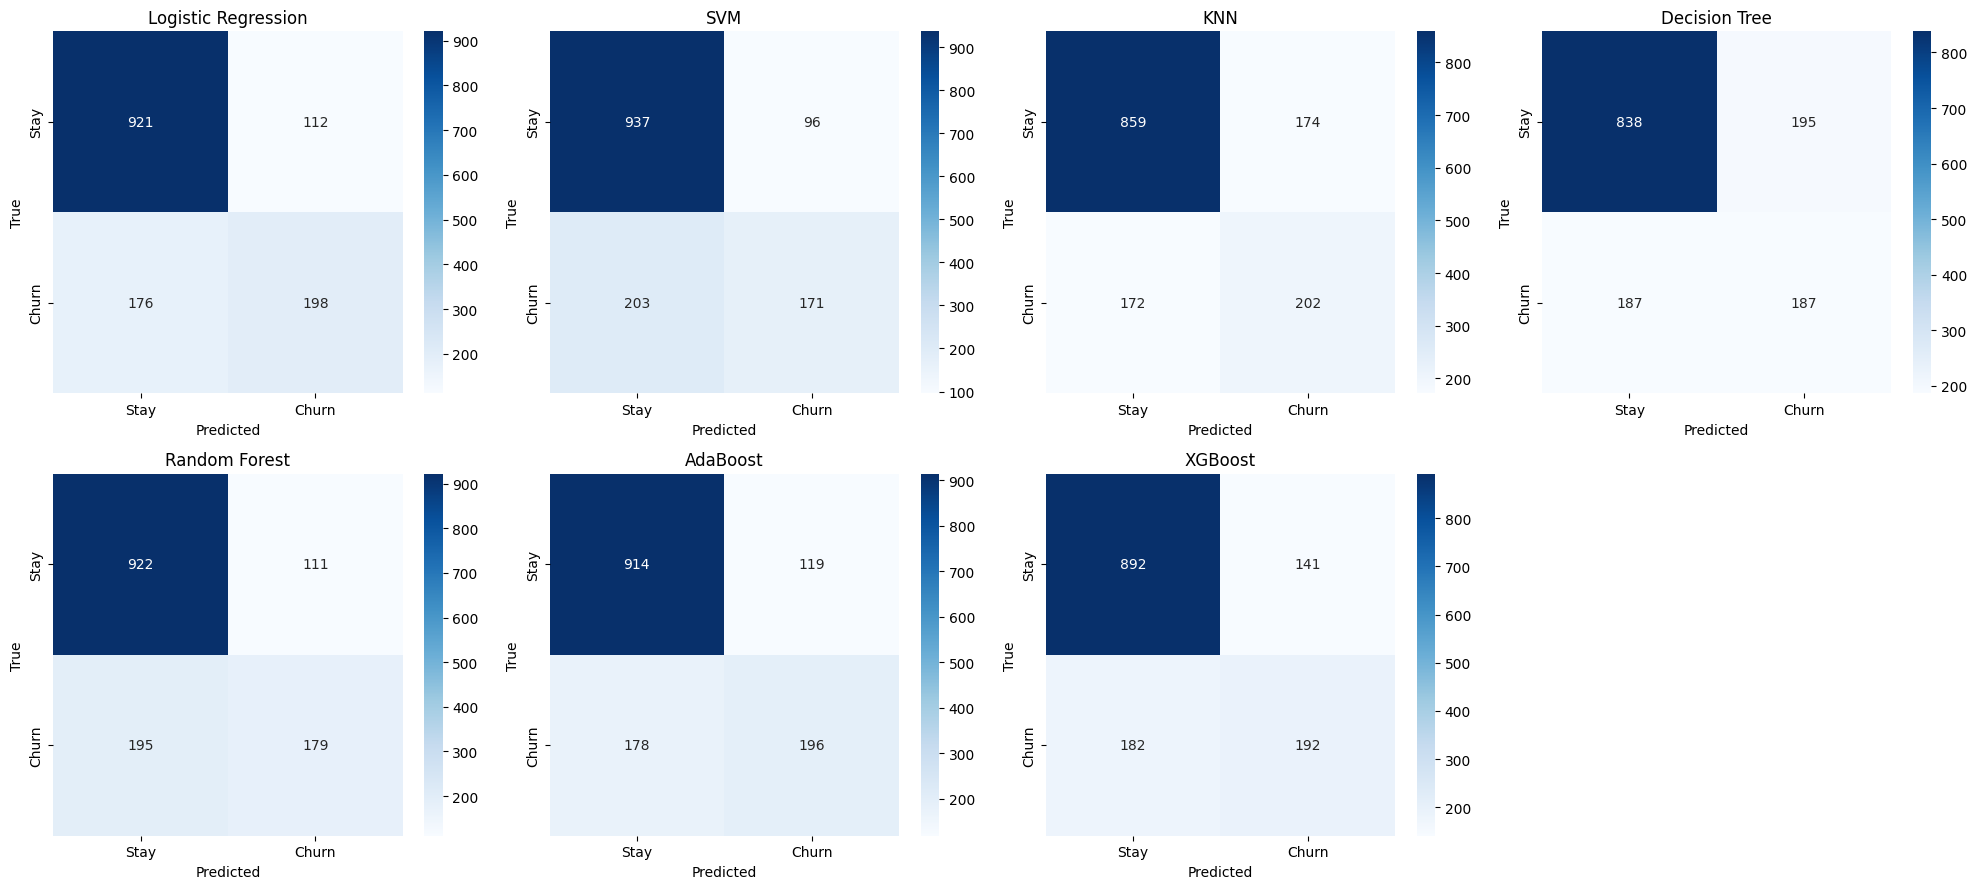

In [44]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.ravel()

for i, name in enumerate(names):
    cm = confusion_matrix(y_test, predictions[name])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Stay', 'Churn'],
                yticklabels=['Stay', 'Churn'], ax=axes[i])
    axes[i].set_title(name)
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('True')

axes[7].axis("off")
plt.tight_layout()
plt.show()

In [45]:
def make_pipe(clf):
    return Pipeline([('scaler', StandardScaler()), ('model', clf)])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'precision': 'precision', 'recall': 'recall', 'f1': 'f1', 'roc_auc': 'roc_auc'}

cv_rows = []
for name, clf in zip(names, model_list):
    s = cross_validate(make_pipe(clf), x_train_raw, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_rows.append({'Model': name, **{k: s[f'test_{k}'].mean() for k in scoring}})

cv_df = pd.DataFrame(cv_rows).sort_values('f1', ascending=False).reset_index(drop=True)
cv_df.round(3)

,Model,precision,recall,f1,roc_auc
0,Logistic Regression,0.662,0.540,0.594,0.847
1,AdaBoost,0.652,0.542,0.592,0.848
2,XGBoost,0.627,0.525,0.571,0.835
3,SVM,0.672,0.477,0.558,0.803
4,Random Forest,0.639,0.492,0.556,0.830
5,KNN,0.549,0.519,0.534,0.780
6,Decision Tree,0.482,0.495,0.488,0.651


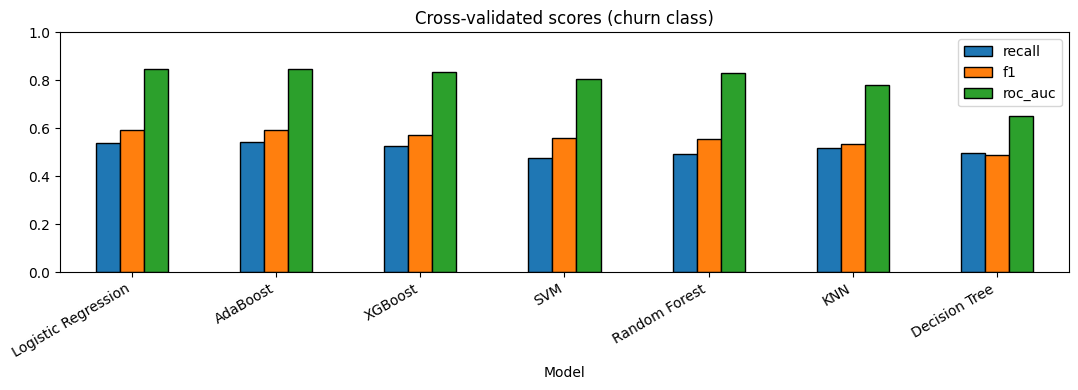

In [46]:
cv_df.set_index('Model')[['recall', 'f1', 'roc_auc']].plot.bar(figsize=(11, 4), edgecolor='black')
plt.title('Cross-validated scores (churn class)'); plt.ylim(0, 1)
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

In [47]:
best_name = cv_df.loc[0, 'Model']
print('Best model :', best_name)

cm = confusion_matrix(y_test, predictions[best_name])
TN, FP, FN, TP = cm.ravel()
print(f"TN={TN}, FP={FP}")
print(f"FN={FN}, TP={TP}")

Best model : Logistic Regression
TN=921, FP=112
FN=176, TP=198


In [48]:
bestModel=model_list[names.index(best_name)]
print("Best Model: ",bestModel)

Best Model:  LogisticRegression(max_iter=5000)


In [49]:
paramGrid={  # CHANGED: keys prefixed with 'model__' because the model is inside a Pipeline
    'model__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'model__solver': ['liblinear', 'lbfgs'],
    'model__class_weight': [None, 'balanced']
}

In [50]:

param_grids = {
    'Logistic Regression': paramGrid,
    'SVM': {'model__C': [0.5, 1, 5], 'model__gamma': ['scale', 0.01], 'model__class_weight': [None, 'balanced']},
    'KNN': {'model__n_neighbors': [5, 11, 21], 'model__weights': ['uniform', 'distance']},
    'Decision Tree': {'model__max_depth': [3, 5, 8], 'model__min_samples_leaf': [5, 20],
                      'model__class_weight': [None, 'balanced']},
    'Random Forest': {'model__n_estimators': [200, 400], 'model__max_depth': [6, 10, None],
                      'model__min_samples_leaf': [2, 5], 'model__class_weight': [None, 'balanced']},
    'AdaBoost': {'model__n_estimators': [100, 200], 'model__learning_rate': [0.05, 0.1, 0.5]},
    'XGBoost': {'model__n_estimators': [100, 200], 'model__max_depth': [3, 5],
                'model__learning_rate': [0.05, 0.1], 'model__scale_pos_weight': [1, 3]},
}

In [51]:

top3 = cv_df['Model'].head(3).tolist()
print('Tuning:', top3)

tuned = {}
for name in top3:
    gs = GridSearchCV(estimator=make_pipe(model_list[names.index(name)]),
                      param_grid=param_grids[name], cv=cv, scoring='f1', verbose=1)
    gs.fit(x_train_raw, y_train)
    tuned[name] = gs
    print(f'{name:20s} CV F1 = {gs.best_score_:.3f}')

best_tuned_name = max(tuned, key=lambda n: tuned[n].best_score_)
grid_search = tuned[best_tuned_name]
print('\nSelected model:', best_tuned_name)

Tuning: ['Logistic Regression', 'AdaBoost', 'XGBoost']
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Logistic Regression  CV F1 = 0.633
Fitting 5 folds for each of 6 candidates, totalling 30 fits
AdaBoost             CV F1 = 0.598
Fitting 5 folds for each of 16 candidates, totalling 80 fits
XGBoost              CV F1 = 0.634

Selected model: XGBoost


In [52]:
print("Best Parameters:")
print(grid_search.best_params_)
print("Best CV F1 Score:")
print(grid_search.best_score_)

Best Parameters:
{'model__learning_rate': 0.05, 'model__max_depth': 5, 'model__n_estimators': 100, 'model__scale_pos_weight': 3}
Best CV F1 Score:
0.6342805360954944


In [53]:
finalModel = grid_search.best_estimator_
print("Optimized Model:")
print(finalModel)

Optimized Model:
Pipeline(steps=[('scaler', StandardScaler()),
                ('model',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device=None,
                               early_stopping_rounds=None,
                               enable_categorical=True, eval_metric=None,
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
              

In [54]:
y_pred_final = finalModel.predict(x_test_raw)
print(classification_report(y_test, y_pred_final))

              precision    recall  f1-score   support

           0       0.91      0.72      0.80      1033
           1       0.51      0.80      0.62       374

    accuracy                           0.74      1407
   macro avg       0.71      0.76      0.71      1407
weighted avg       0.80      0.74      0.75      1407



In [55]:
print("Accuracy:", accuracy_score(y_test, y_pred_final))
print("Precision:", precision_score(y_test, y_pred_final))
print("Recall:", recall_score(y_test, y_pred_final))
print("F1-Score:", f1_score(y_test, y_pred_final))

Accuracy: 0.7391613361762616
Precision: 0.5058823529411764
Recall: 0.8048128342245989
F1-Score: 0.6212590299277606


ROC-AUC: 0.837


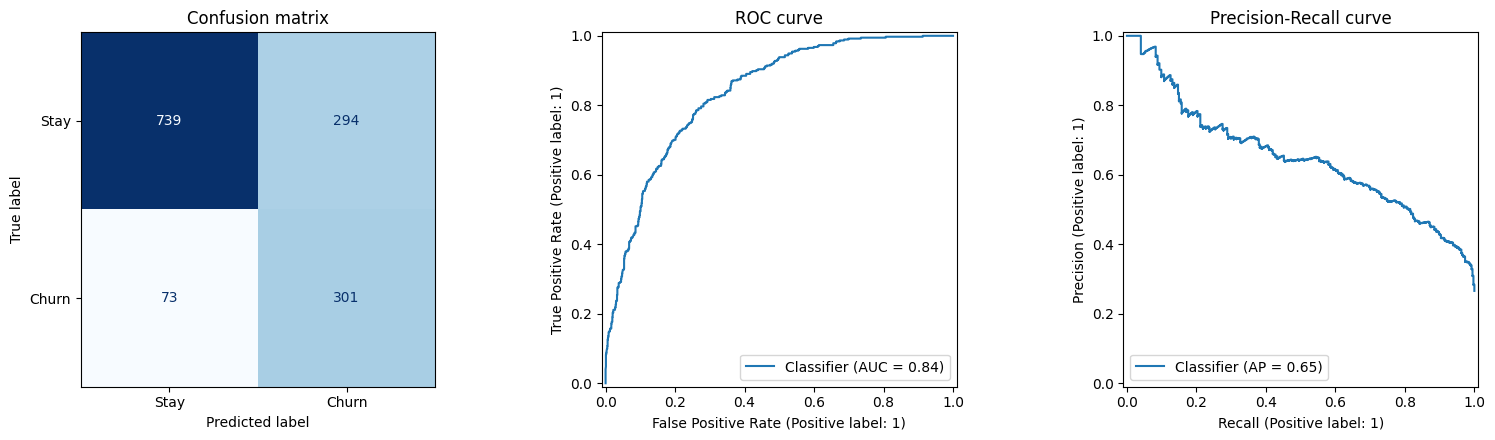

In [56]:
y_proba = finalModel.predict_proba(x_test_raw)[:, 1]
print('ROC-AUC:', round(roc_auc_score(y_test, y_proba), 3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_final, display_labels=['Stay', 'Churn'],
                                        cmap='Blues', ax=ax[0], colorbar=False)
ax[0].set_title('Confusion matrix')
RocCurveDisplay.from_predictions(y_test, y_proba, ax=ax[1]); ax[1].set_title('ROC curve')
PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=ax[2]); ax[2].set_title('Precision-Recall curve')
plt.tight_layout(); plt.show()

In [57]:
rows = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (y_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    rows.append({'threshold': t, 'recall': tp / (tp + fn), 'precision': tp / (tp + fp),
                 'flagged customers': tp + fp, 'missed churners': fn})
pd.DataFrame(rows).round(3)

,threshold,recall,precision,flagged customers,missed churners
0,0.2,0.957,0.387,925,16
1,0.3,0.904,0.420,804,36
2,0.4,0.858,0.463,694,53
3,0.5,0.805,0.506,595,73
4,0.6,0.714,0.556,480,107
5,0.7,0.594,0.620,358,152


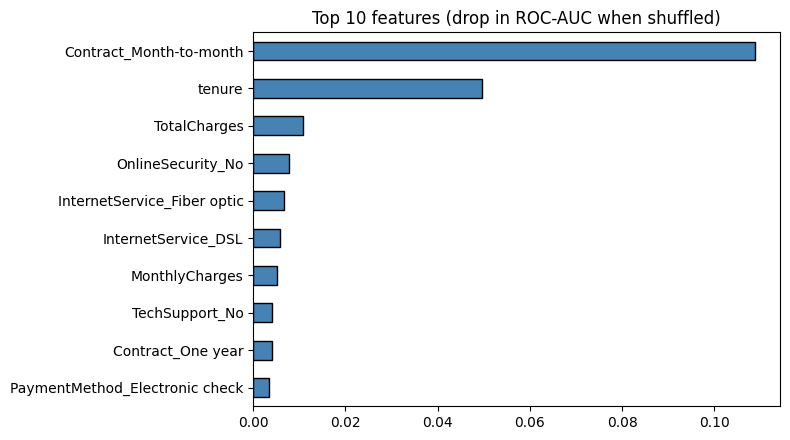

In [58]:
imp = permutation_importance(finalModel, x_test_raw, y_test, scoring='roc_auc',
                             n_repeats=10, random_state=42, n_jobs=-1)
imp_s = pd.Series(imp.importances_mean, index=x_test_raw.columns).sort_values().tail(10)
imp_s.plot.barh(figsize=(8, 4.5), color='steelblue', edgecolor='black')
plt.title('Top 10 features (drop in ROC-AUC when shuffled)'); plt.tight_layout(); plt.show()

In [59]:
import joblib

In [60]:
model_data = {
    'model': finalModel,
    'feature_columns': x.columns.tolist()
}

In [61]:
joblib.dump(model_data, 'best_model.pkl')

['best_model.pkl']

In [62]:
loaded_data = joblib.load('best_model.pkl')

In [63]:
loaded_model = loaded_data['model']
feature_columns = loaded_data['feature_columns']

In [64]:
print("Model Loaded Successfully!")
print("Model:")
print(loaded_model)
print("Features:")
print(feature_columns)

Model Loaded Successfully!
Model:
Pipeline(steps=[('scaler', StandardScaler()),
                ('model',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device=None,
                               early_stopping_rounds=None,
                               enable_categorical=True, eval_metric=None,
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=na

In [65]:
print(loaded_model.predict_proba(x_test_raw.head(3))[:, 1].round(3))

[0.036 0.828 0.061]
